In [6]:
import pandas as pd
import matplotlib.pyplot as plt

#Task 1
df = pd.read_csv("SuperStore.csv", encoding="latin1")

df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M"))["Sales"].sum()

months = monthly_sales.index.astype(str)
sales = monthly_sales.values

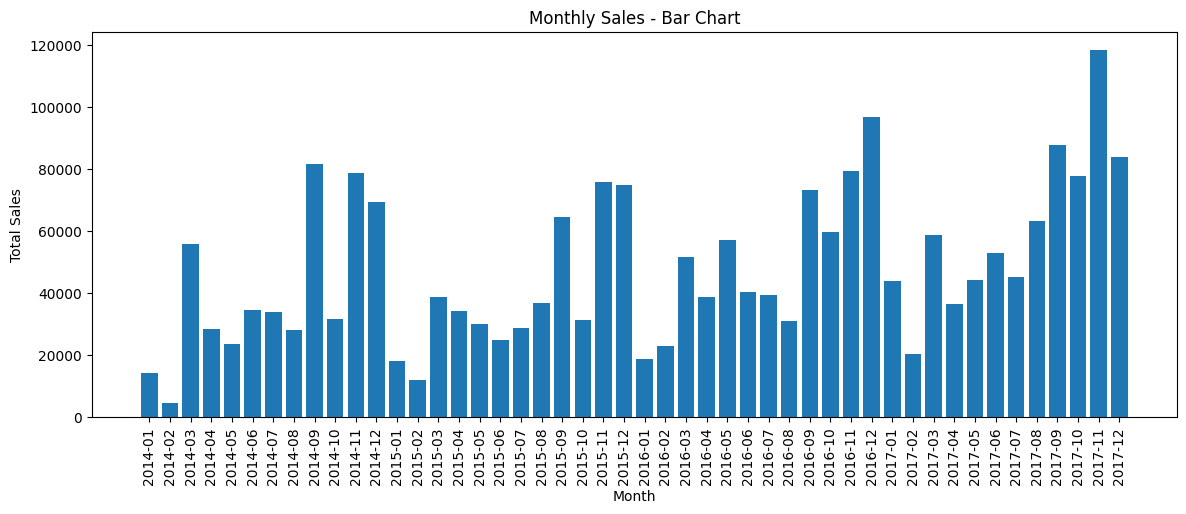

In [7]:
plt.figure(figsize=(14, 5))

plt.bar(months, sales)

plt.title("Monthly Sales - Bar Chart")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.show()

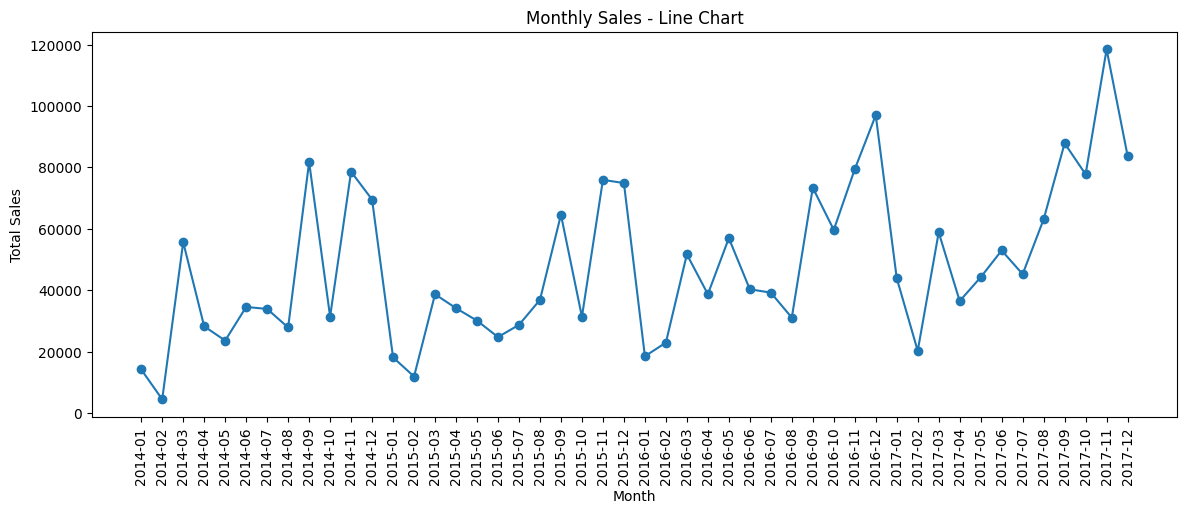

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(months, sales, marker="o")

plt.title("Monthly Sales - Line Chart")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.show()

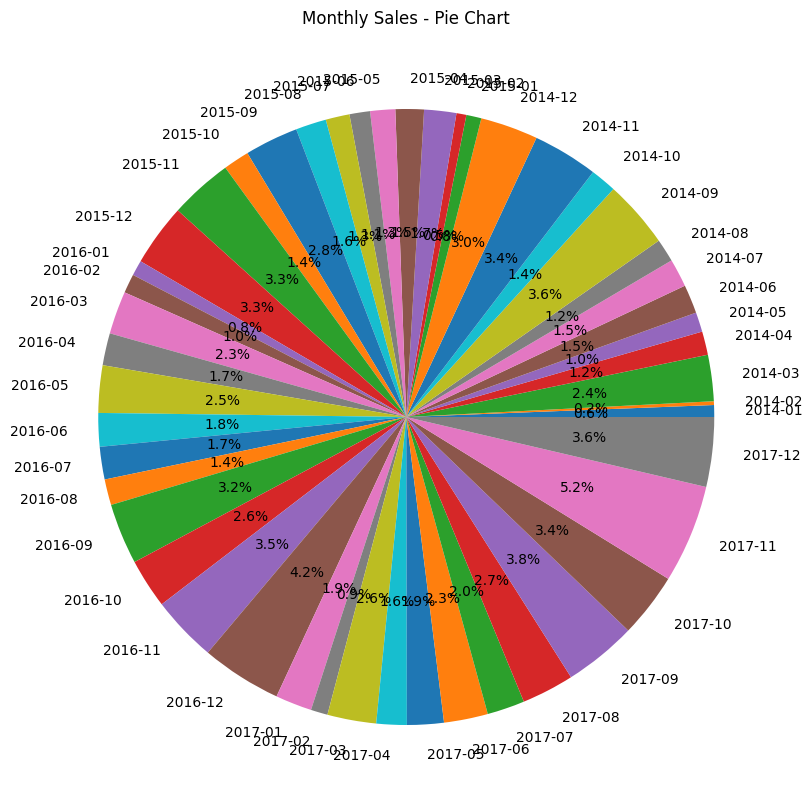

In [12]:
plt.figure(figsize=(10, 10))

plt.pie(
    sales,
    labels=months,
    autopct="%1.1f%%"
)

plt.title("Monthly Sales - Pie Chart")

plt.show()

# The line chart shows the trend best because the points are connected in chronological order, making increases, decreases,
# and fluctuations in monthly sales easy to identify. The pie chart hides the trend because it focuses on each month's proportion
# of total sales rather than the order of the months, making changes over time difficult to see.

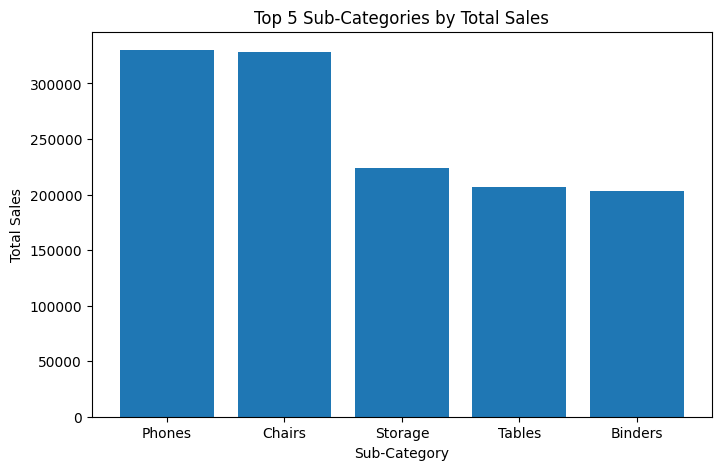

In [14]:
#Task 2
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum()

top5 = subcategory_sales.nlargest(5)

plt.figure(figsize=(8, 5))
plt.bar(top5.index, top5.values)

plt.title("Top 5 Sub-Categories by Total Sales")
plt.xlabel("Sub-Category")
plt.ylabel("Total Sales")

plt.show()

# A bar chart is appropriate because it makes it easy to compare total sales across the five sub-categories. 
# A pie chart would underperform because comparing slice sizes is harder than comparing bar lengths.

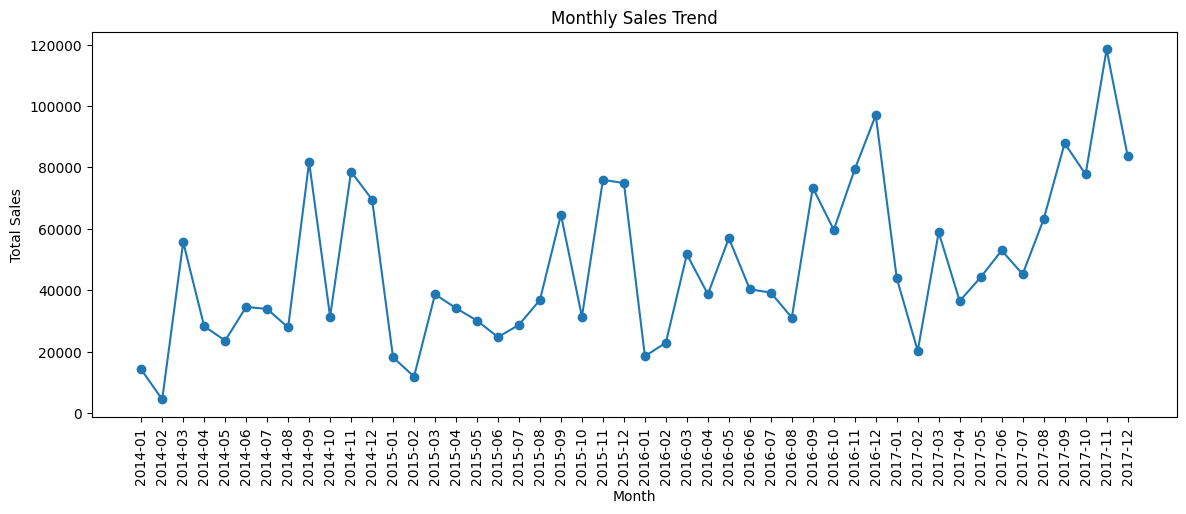

In [15]:
months = monthly_sales.index.astype(str)
sales = monthly_sales.values

plt.figure(figsize=(14, 5))
plt.plot(months, sales, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.show()

# A line chart is appropriate because the months are ordered chronologically 
# and the connected points clearly show increases, decreases, and fluctuations in sales over time. 
# A bar chart would be less effective for showing the overall trend across many months.

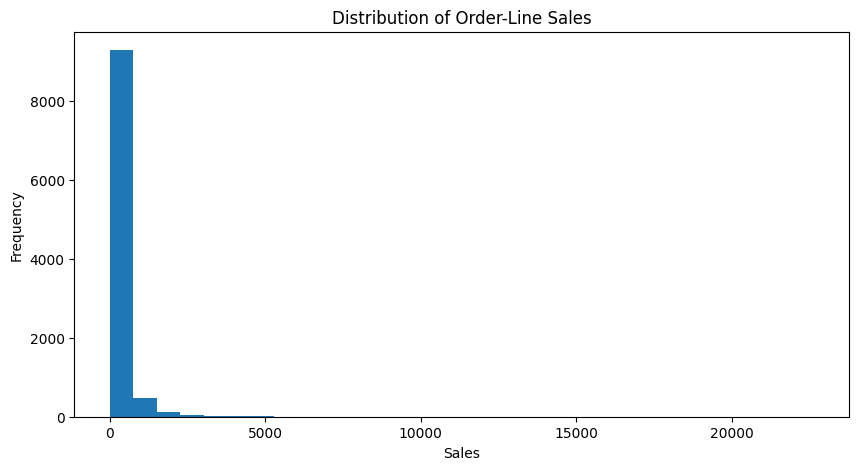

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(df["Sales"], bins=30)

plt.title("Distribution of Order-Line Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

# A histogram is appropriate because it shows the distribution and frequency of the raw order-line sales values.
# A bar chart of averages would hide the spread and variation of the individual sales values.

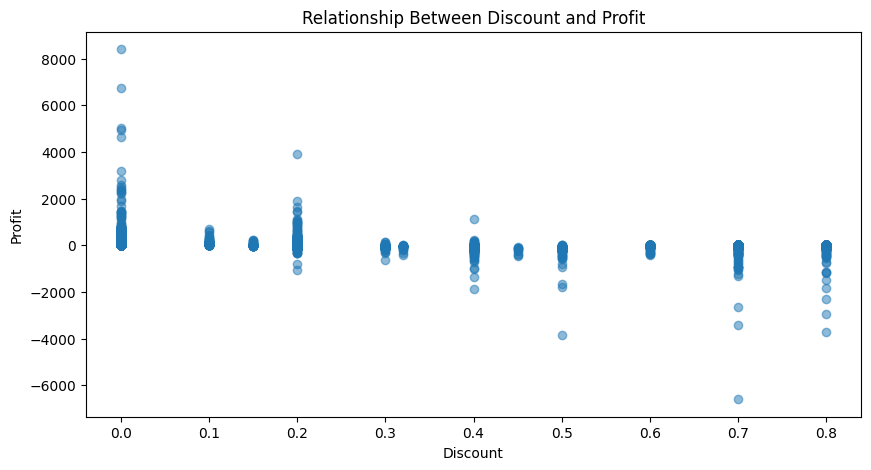

In [19]:
plt.figure(figsize=(10, 5))

plt.scatter(df["Discount"], df["Profit"], alpha=0.5)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

# A scatter plot is appropriate because it shows the relationship between two numerical variables, discount and profit, using individual observations. 
# A line chart would be a weak choice because it could imply an ordered sequence between individual observations.

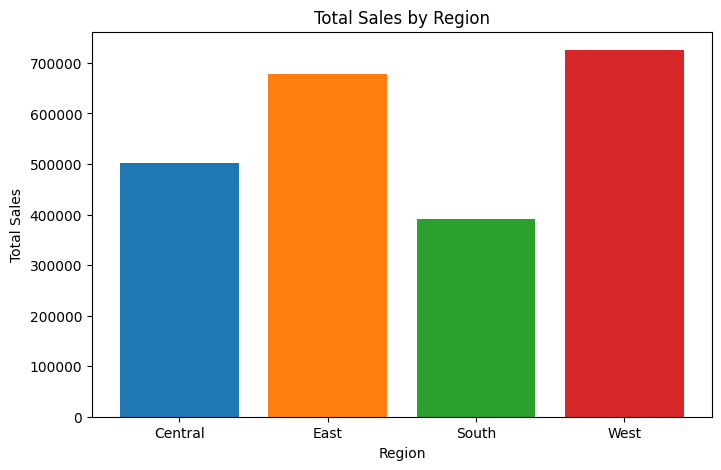

In [20]:
#Task 3
region_sales = df.groupby("Region")["Sales"].sum()
plt.figure(figsize=(8, 5))

plt.bar(
    region_sales.index,
    region_sales.values,
    color=plt.cm.tab10(range(len(region_sales)))
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

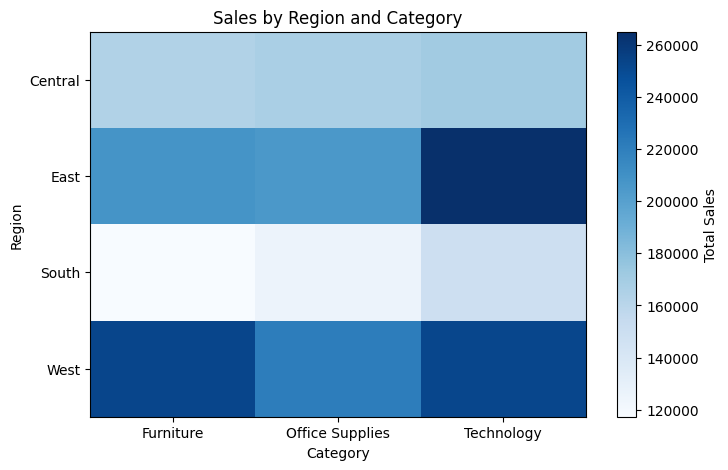

In [25]:
region_category_sales = df.pivot_table(
    values="Sales",
    index="Region",
    columns="Category",
    aggfunc="sum"
)

plt.figure(figsize=(8, 5))

plt.imshow(
    region_category_sales,
    cmap="Blues",
    aspect="auto"
)

plt.colorbar(label="Total Sales")

plt.xticks(
    range(len(region_category_sales.columns)),
    region_category_sales.columns
)

plt.yticks(
    range(len(region_category_sales.index)),
    region_category_sales.index
)

plt.title("Sales by Region and Category")
plt.xlabel("Category")
plt.ylabel("Region")

plt.show()

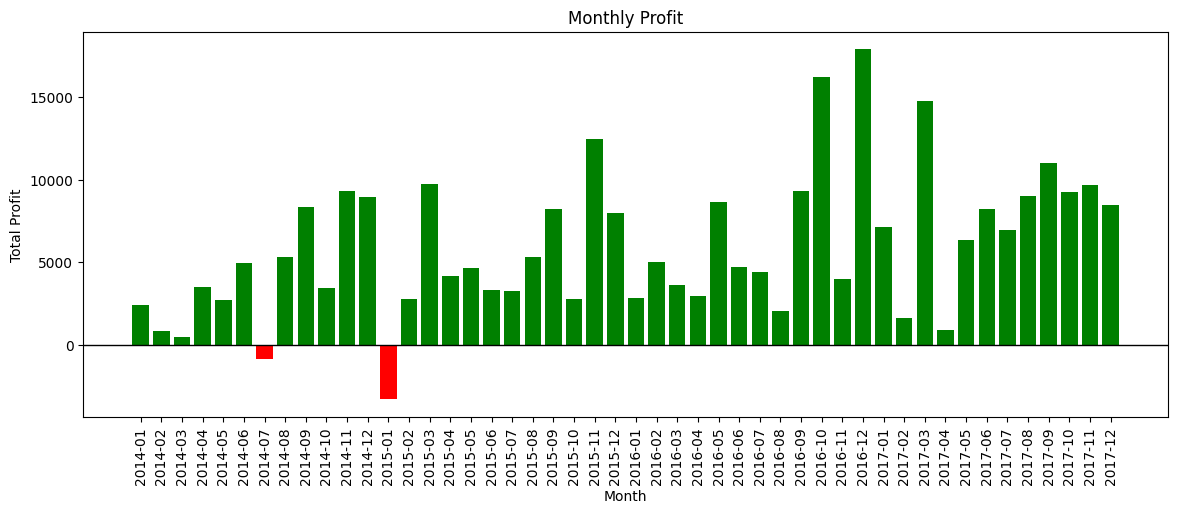

In [27]:
monthly_profit = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Profit"].sum()
profit_months = monthly_profit.index.astype(str)
profit_values = monthly_profit.values

plt.figure(figsize=(14, 5))

colors = ["red" if value < 0 else "green" for value in monthly_profit]

plt.bar(profit_months, profit_values, color=colors)

plt.axhline(0, color="black", linewidth=1)

plt.title("Monthly Profit")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)

plt.show()

In [28]:
#Task 4
def contrast_ratio(rgb1, rgb2):
    def luminance(rgb):
        rgb = [x / 255 for x in rgb]

        rgb = [
            ((x + 0.055) / 1.055) ** 2.4 if x > 0.04045 else x / 12.92
            for x in rgb
        ]

        return (
            0.2126 * rgb[0] +
            0.7152 * rgb[1] +
            0.0722 * rgb[2]
        )

    L1 = luminance(rgb1)
    L2 = luminance(rgb2)

    if L1 < L2:
        L1, L2 = L2, L1

    return (L1 + 0.05) / (L2 + 0.05)

In [29]:
colors = plt.cm.tab10(range(len(region_sales)))

rgb_colors = [
    tuple(int(value * 255) for value in color[:3])
    for color in colors
]

rgb_colors

[(31, 119, 180), (255, 127, 14), (44, 160, 44), (214, 39, 40)]

In [30]:
for i, color in enumerate(rgb_colors):
    ratio = contrast_ratio(color, (255, 255, 255))

    if ratio < 4.5:
        print(f"Color {i+1}: {color} -> {ratio:.2f}:1 FAIL")
    else:
        print(f"Color {i+1}: {color} -> {ratio:.2f}:1 PASS")

Color 1: (31, 119, 180) -> 4.82:1 PASS
Color 2: (255, 127, 14) -> 2.53:1 FAIL
Color 3: (44, 160, 44) -> 3.40:1 FAIL
Color 4: (214, 39, 40) -> 5.02:1 PASS


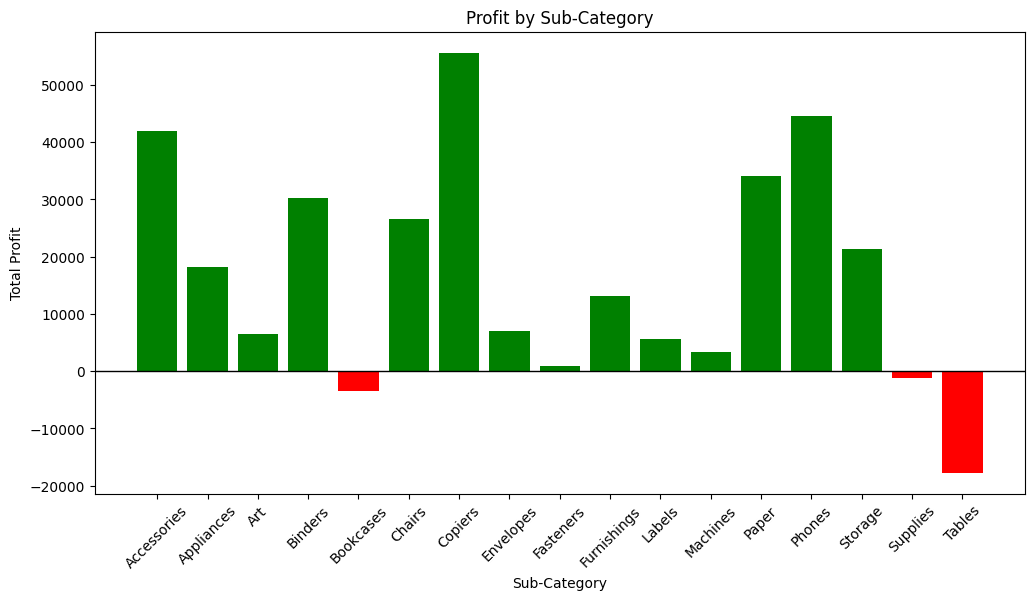

In [32]:
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()
plt.figure(figsize=(12, 6))

colors = [
    "green" if value >= 0 else "red"
    for value in subcategory_profit
]

plt.bar(
    subcategory_profit.index,
    subcategory_profit.values,
    color=colors
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)

plt.show()

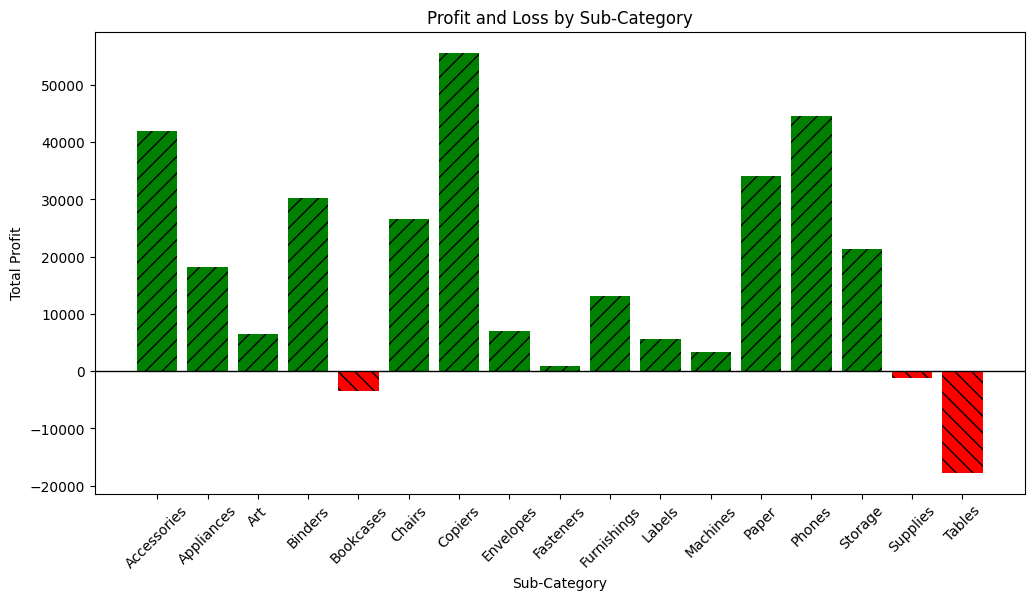

In [33]:
plt.figure(figsize=(12, 6))

for i, value in enumerate(subcategory_profit):
    if value >= 0:
        color = "green"
        hatch = "//"
    else:
        color = "red"
        hatch = "\\\\"

    plt.bar(
        i,
        value,
        color=color,
        hatch=hatch
    )

plt.axhline(0, color="black", linewidth=1)

plt.xticks(
    range(len(subcategory_profit)),
    subcategory_profit.index,
    rotation=45
)

plt.title("Profit and Loss by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")

plt.show()

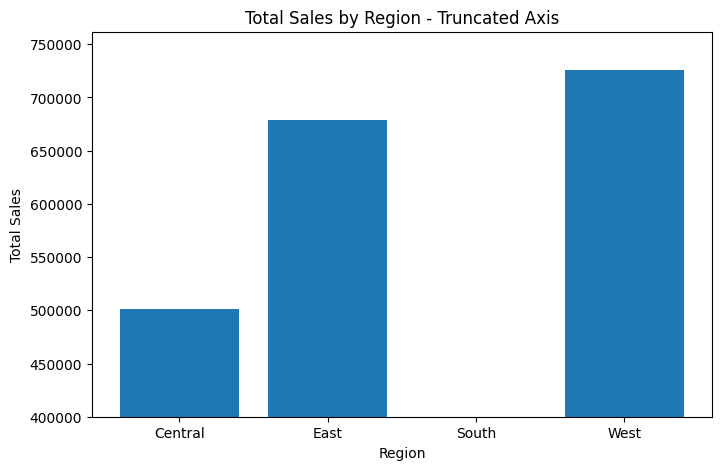

In [34]:
#Task 5
plt.figure(figsize=(8, 5))

plt.bar(region_sales.index, region_sales.values)

plt.title("Total Sales by Region - Truncated Axis")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.ylim(bottom=400000)

plt.show()
# Distortion mechanism: Truncated y-axis; starting the y-axis above zero exaggerates the visual differences between regional sales.

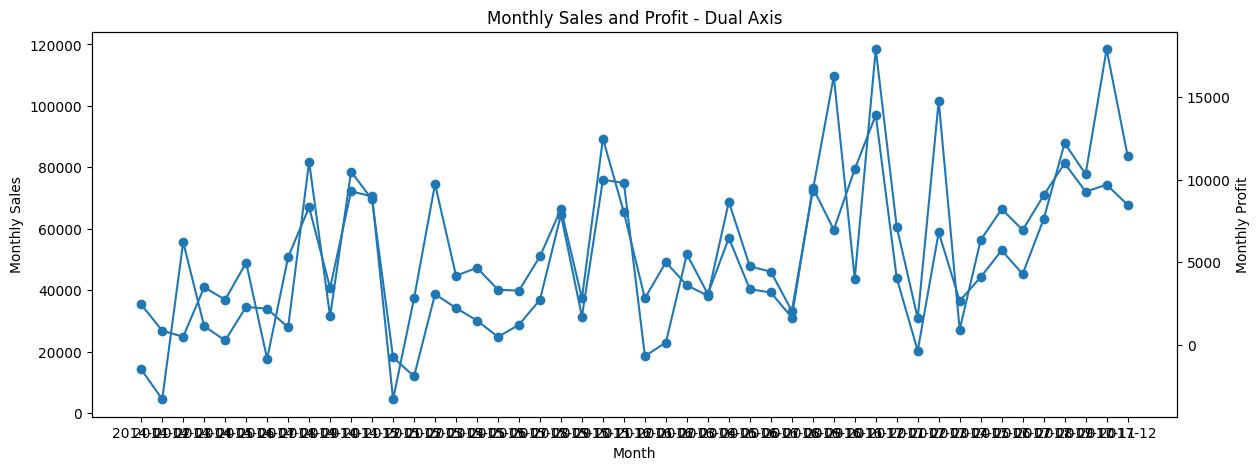

In [36]:
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(
    months,
    monthly_sales.values,
    marker="o"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Monthly Sales")

ax2 = ax1.twinx()

ax2.plot(
    profit_months,
    monthly_profit.values,
    marker="o"
)

ax2.set_ylabel("Monthly Profit")

plt.title("Monthly Sales and Profit - Dual Axis")

plt.xticks(rotation=90)

plt.show()
# Distortion mechanism: Dual y-axes using separate scales can make two measures appear correlated even when their relationship is weak or unrelated.

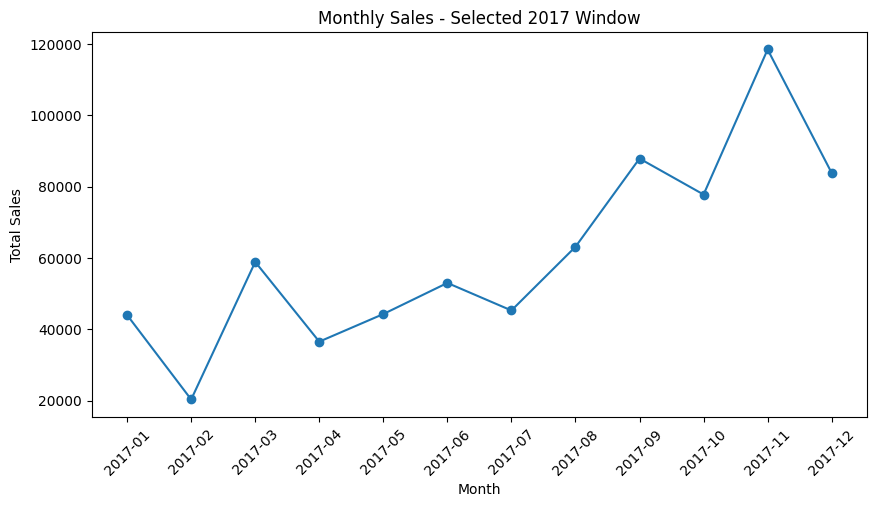

In [37]:
cherry_picked = monthly_sales[
    monthly_sales.index.year == 2017
]

plt.figure(figsize=(10, 5))

plt.plot(
    cherry_picked.index.astype(str),
    cherry_picked.values,
    marker="o"
)

plt.title("Monthly Sales - Selected 2017 Window")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.show()
# Distortion mechanism: Cherry-picked date window — showing only a selected period hides the surrounding trend
# and can create a misleading impression of overall performance.

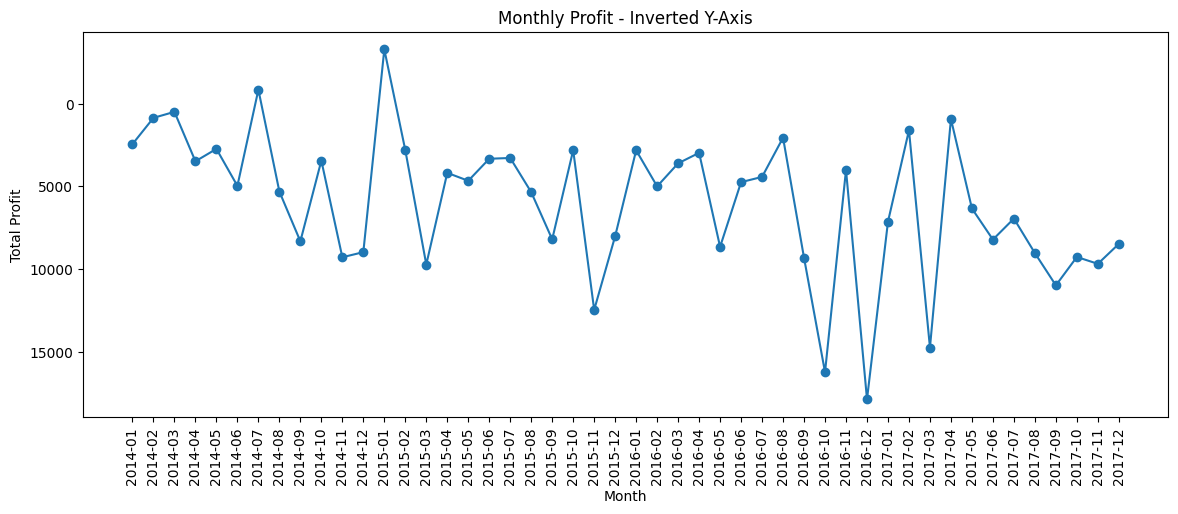

In [38]:
plt.figure(figsize=(14, 5))

plt.plot(profit_months, profit_values, marker="o")

plt.title("Monthly Profit - Inverted Y-Axis")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)

plt.gca().invert_yaxis()

plt.show()
# Distortion mechanism: Inverted y-axis — reversing the vertical scale makes increases in profit appear
# as downward movement and can make the trend look opposite to the actual data.

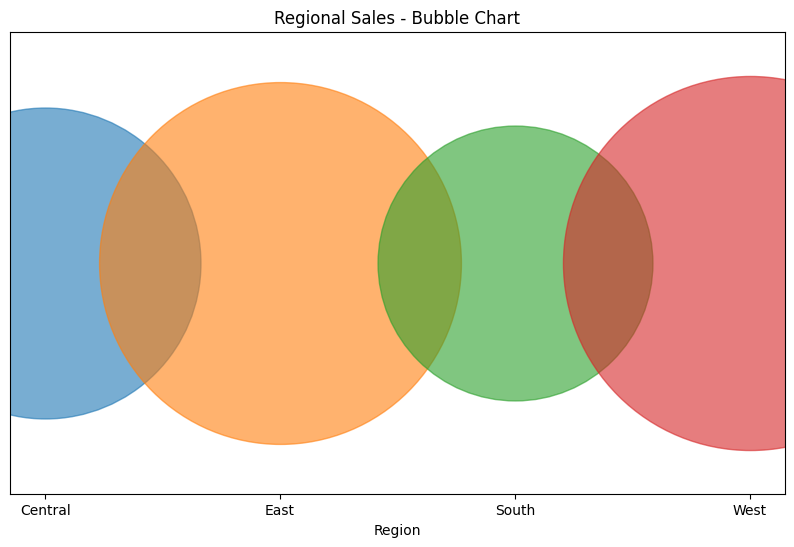

In [39]:
plt.figure(figsize=(10, 6))

values = region_sales.values

for i, value in enumerate(values):
    plt.scatter(
        i,
        1,
        s=value / 10,
        alpha=0.6
    )

plt.xticks(range(len(region_sales)), region_sales.index)
plt.yticks([])
plt.title("Regional Sales - Bubble Chart")
plt.xlabel("Region")

plt.show()
# Distortion mechanism: Bubble radius is scaled by sales,
# causing the circle area to grow much faster than the actual values and exaggerating differences between regions.

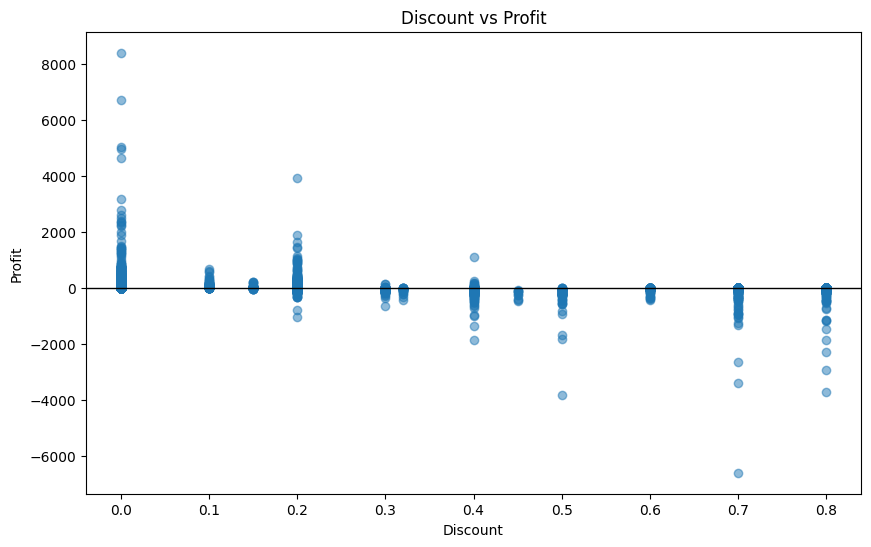

In [40]:
#Task 6
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Discount"],
    df["Profit"],
    alpha=0.5
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()
# Each point represents an order line, so the chart shows the actual relationship between discount and profit without hiding individual observations.

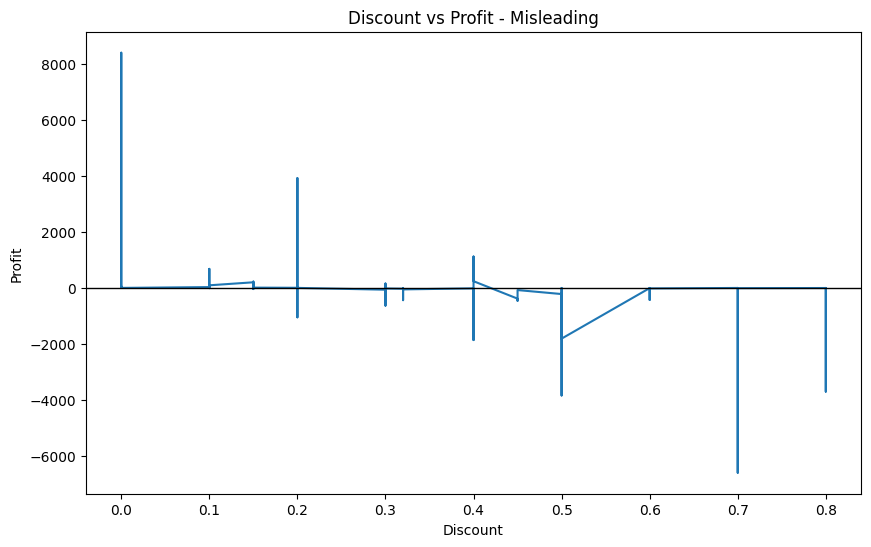

In [41]:
misleading = df.sort_values("Discount")

plt.figure(figsize=(10, 6))

plt.plot(
    misleading["Discount"],
    misleading["Profit"]
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Discount vs Profit - Misleading")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

Chart choice: A scatter plot is appropriate because both discount and profit are numerical variables, and it allows us to see the relationship and spread of individual observations.

Color choice: A simple single-color chart is used because color is not needed to represent another variable. This avoids unnecessary visual complexity.

Accessibility: The chart does not rely on color to communicate meaning, and the zero-profit reference line makes positive and negative profit easier to distinguish. The chart also has clear axis labels and a descriptive title.